[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E7%9B%B4%E6%8E%A5%E4%BD%BF%E7%94%A8pandas%E7%B9%AA%E5%88%B6%E5%9C%96%E8%A1%A8/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E4%B8%80%E8%A1%8C%E7%95%AB%E5%87%BA%E5%8F%B0%E7%81%A3%E7%9A%84%E5%85%AD%E5%80%8B%E6%95%85%E4%BA%8B.ipynb)

# 🖼️ 一行程式，畫出台灣的六個故事

> 🎯 **情境**：前面幾章你已經用過 YouBike、電影票房、台電用電、空氣品質、捷運這幾份真實資料。這一章是「**成果發表會**」：每份資料整理好之後，只要在表格後面加上 `.plot()`，一行就能畫出圖；再搭配 **seaborn** 畫出統計圖。你要做出六張可以直接放進簡報的圖，每一張講一個台灣的故事。

| 素材檔案 | 內容 |
| --- | --- |
| `臺北市YouBike每月使用量.csv` | 臺北市 YouBike 每月騎乘次數（Big5） |
| `全國電影票房_2016至今.json` | 文化部全國電影票房（JSON） |
| `台電各縣市用電統計.csv` | 台電各縣市每月售電量 |
| `日空氣品質指標_近一年.csv` | 環境部近一年每日 AQI |
| `臺北捷運各站分時進出量_202603.csv` | 臺北捷運 2026 年 3 月各站每小時進出站人次 |

| 📡 資料來源（政府資料開放平台） | 提供機關 | 下載日期 |
| --- | --- | --- |
| [YouBike臺北市站位每月使用量](https://data.gov.tw/dataset/135775) | 臺北市政府交通局 | 2026-10-24 |
| [全國電影票房統計數據](https://data.gov.tw/dataset/94224) | 文化部 | 2026-10-24 |
| [台灣電力公司各縣市住宅、服務業及機關用電統計資料](https://data.gov.tw/dataset/29935) | 台灣電力股份有限公司 | 2026-10-24 |
| [日空氣品質指標(AQI)](https://data.gov.tw/dataset/40507) | 環境部 | 2026-10-24 |
| [臺北捷運各站分時進出量統計](https://data.gov.tw/dataset/128506) | 臺北大眾捷運股份有限公司 | 2026-10-24 |

> ✅ 這些都是**真實的政府開放資料**，依「政府資料開放授權條款－第1版」使用。課堂上統一使用上表日期的快照，所以每個人跑出來的數字都一樣。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    '臺北市YouBike每月使用量.csv',
    '全國電影票房_2016至今.json',
    '台電各縣市用電統計.csv',
    '日空氣品質指標_近一年.csv',
    '臺北捷運各站分時進出量_202603.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E7%9B%B4%E6%8E%A5%E4%BD%BF%E7%94%A8pandas%E7%B9%AA%E5%88%B6%E5%9C%96%E8%A1%A8/%E7%9B%B4%E6%8E%A5%E4%BD%BF%E7%94%A8pandas%E7%B9%AA%E5%88%B6%E5%9C%96%E8%A1%A8_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['臺北市YouBike每月使用量.csv', '全國電影票房_2016至今.json', '台電各縣市用電統計.csv', '日空氣品質指標_近一年.csv', '臺北捷運各站分時進出量_202603.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

## 故事 1：YouBike 騎乘量一路往上——`Series.plot()` 折線圖

**白話說明**：DataFrame / Series 後面直接接 `.plot()`，**索引自動變成 X 軸、數值變成 Y 軸**。索引是日期時，X 軸就會是時間軸。

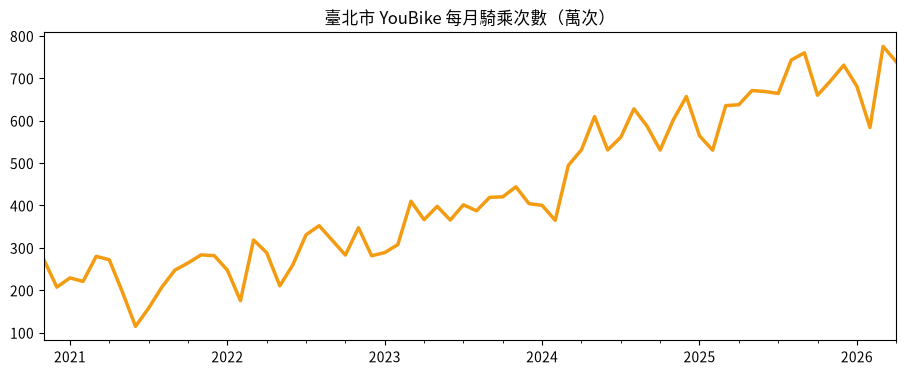

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

bike = pd.read_csv('臺北市YouBike每月使用量.csv', encoding='cp950')
bike['月份'] = pd.to_datetime(bike['西元年'].astype(str) + '-' + bike['月份'].astype(str) + '-01')
rides = bike.set_index('月份')['臺北市YouBike每月使用量（次數）'] / 1e4       # 單位：萬次

ax = rides.plot(figsize=(11, 4), color='#F39C12', linewidth=2.5, title='臺北市 YouBike 每月騎乘次數（萬次）')
ax.set_xlabel('')
plt.show()

## 故事 2：疫情讓電影院少了一半的觀眾——長條圖＋標註

**白話說明**：`plot.bar()` 畫長條；`ax.annotate` 在圖上加說明文字和箭頭，**讓讀者一眼看到重點**。

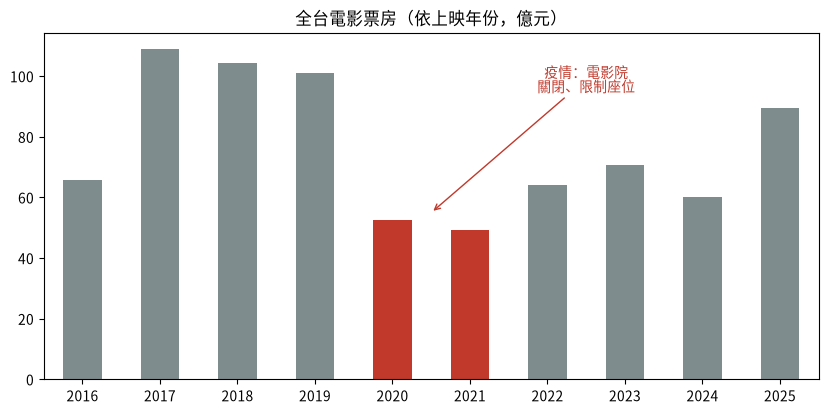

In [4]:
import json

with open('全國電影票房_2016至今.json', encoding='utf-8-sig') as f:
    movies = pd.DataFrame(json.load(f)['List'])
movies = movies[movies['TotalAmounts'] > 0]
movies['年'] = movies['ReleaseDate'].str[:4].astype(int)

by_year = movies[movies['年'].between(2016, 2025)].groupby('年')['TotalAmounts'].sum() / 1e8   # 億元
colors = ['#C0392B' if y in (2020, 2021) else '#7F8C8D' for y in by_year.index]
ax = by_year.plot.bar(figsize=(10, 4.5), color=colors, title='全台電影票房（依上映年份，億元）', rot=0)
ax.annotate('疫情：電影院\n關閉、限制座位', xy=(4.5, 55), xytext=(6.5, 95), ha='center',
            arrowprops=dict(arrowstyle='->', color='#C0392B'), color='#C0392B')
ax.set_xlabel('')
plt.show()

> 💡 **看懂結果**：2017～2019 年每年約 100 億，2020、2021 年掉到 50 億左右——**少了一半**；2025 年才回到快 90 億。

## 故事 3：台灣的電都去哪了？——堆疊面積圖

**白話說明**：`plot.area()` 畫**堆疊面積圖**：每一層是一種用電類別，整體高度是總用電，適合看「總量與組成一起變化」。

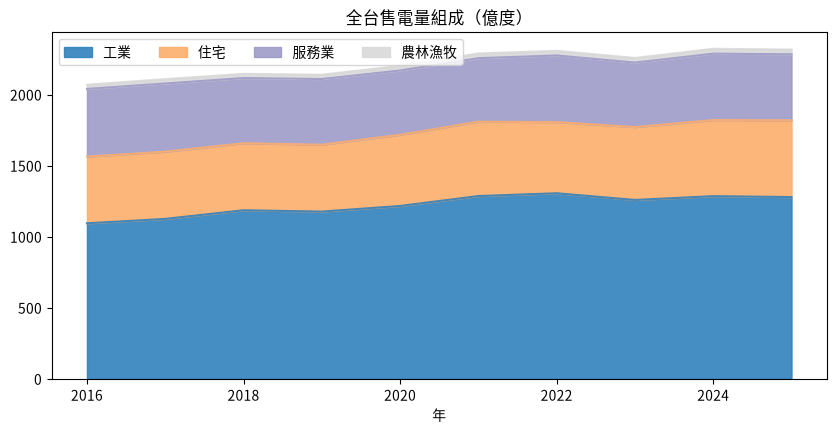

In [5]:
power = pd.read_csv('台電各縣市用電統計.csv', thousands=',', usecols=range(5)).dropna(subset=['年月'])
power['年'] = (power['年月'] // 100 + 1911).astype(int)
mix = (power[power['年'].between(2016, 2025)]
       .pivot_table(index='年', columns='用電性質', values='售電量(度)', aggfunc='sum') / 1e8)   # 億度
mix = mix[['工業', '住宅', '服務業', '農林漁牧']]

ax = mix.plot.area(figsize=(10, 4.5), colormap='tab20c', alpha=0.9, title='全台售電量組成（億度）')
ax.legend(loc='upper left', ncol=4)
plt.show()

> 💡 **看懂結果**：最下面的**工業**是最大的一層，2016 到 2022 年成長了將近兩成（半導體等產業擴廠），近幾年持平；**住宅**用電則是穩定地慢慢增加（十年多了約 15%），服務業幾乎沒變。

## 故事 4：冬天的空氣比較差——seaborn 箱型圖

**白話說明**：**箱型圖**一次畫出「中位數（中間那條線）、大部分資料的範圍（箱子）、極端值（點）」，最適合比較好幾組資料的**分布**。seaborn 只要指定 `x`、`y`。

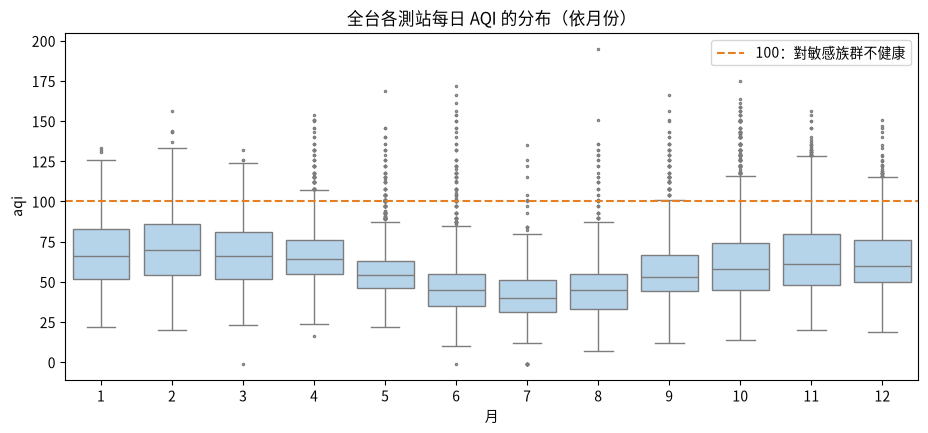

In [6]:
import seaborn as sns

aqi = pd.read_csv('日空氣品質指標_近一年.csv', parse_dates=['monitordate'])
aqi['月'] = aqi['monitordate'].dt.month

plt.figure(figsize=(11, 4.5))
sns.boxplot(data=aqi, x='月', y='aqi', color='#AED6F1', fliersize=1.5)
plt.axhline(100, color='#E67E22', linestyle='--', label='100：對敏感族群不健康')
plt.title('全台各測站每日 AQI 的分布（依月份）'); plt.legend()
plt.show()

> 💡 **看懂結果**：7 月的箱子又低又扁——**幾乎全台都是好空氣**；1～4 月、11 月的箱子高、上面的點（極端值）多，**冬春季要特別注意**。

## 故事 5：一週七天的捷運人潮——seaborn 熱力圖

**白話說明**：先整理成「星期 × 時段」的表（平均每天進站人次），`sns.heatmap` 一行畫出熱力圖：越亮的格子越擠。

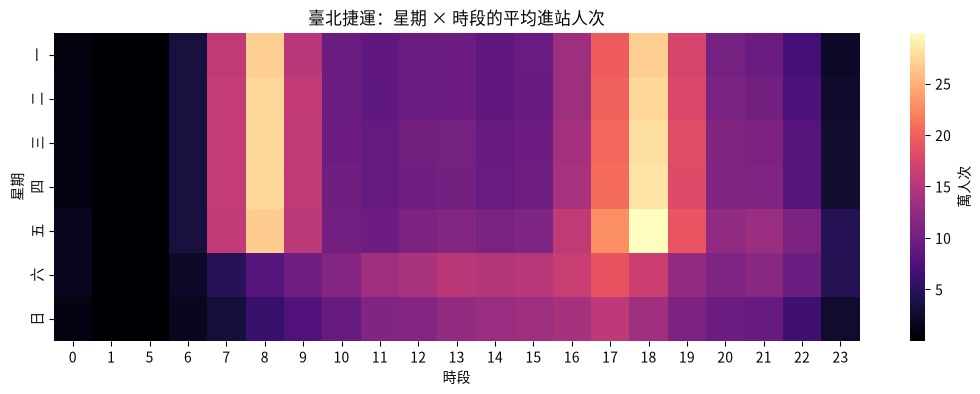

In [7]:
mrt = pd.read_csv('臺北捷運各站分時進出量_202603.csv', parse_dates=['日期'])
mrt['星期'] = mrt['日期'].dt.day_of_week
per_day = mrt.groupby(['日期', '星期', '時段'], as_index=False)['進站人次'].sum()
table = per_day.pivot_table(index='星期', columns='時段', values='進站人次', aggfunc='mean') / 1e4   # 萬人次
table.index = ['一', '二', '三', '四', '五', '六', '日']

plt.figure(figsize=(13, 4))
sns.heatmap(table, cmap='magma', cbar_kws={'label': '萬人次'})
plt.title('臺北捷運：星期 × 時段的平均進站人次'); plt.ylabel('星期')
plt.show()

> 💡 **看懂結果**：平日的早上 8 點、晚上 6 點是兩條**亮線**——通勤尖峰；週末的亮區往中午、下午移，而且比較分散。**一張圖就是整座城市的作息表。**

## 故事 6：美國片、日本片、國片——seaborn 散佈圖

**白話說明**：`sns.scatterplot` 用 `hue` 依類別上不同顏色。票房差距太大（從幾百元到 9 億），所以 Y 軸用**對數刻度**（`plt.yscale('log')`），小片和大片才能放在同一張圖裡。

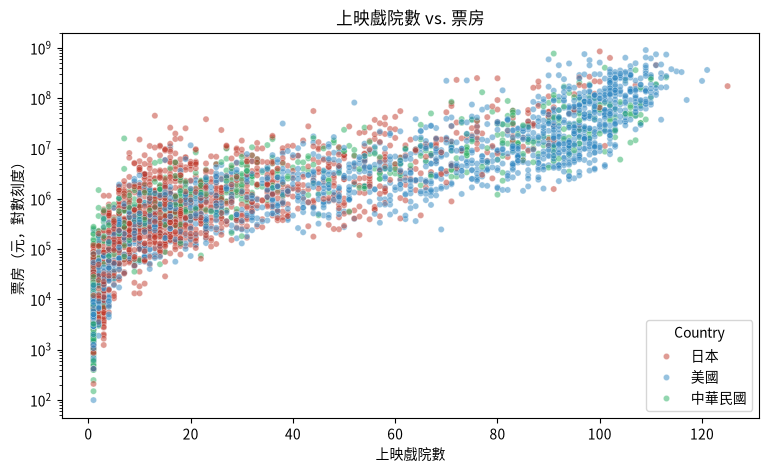

In [8]:
top3 = movies[movies['Country'].isin(['美國', '日本', '中華民國']) & (movies['年'] >= 2016)]

plt.figure(figsize=(9, 5))
sns.scatterplot(data=top3, x='TheaterCount', y='TotalAmounts', hue='Country', alpha=0.5, s=20,
                palette={'美國': '#2E86C1', '日本': '#C0392B', '中華民國': '#27AE60'})
plt.yscale('log')
plt.xlabel('上映戲院數'); plt.ylabel('票房（元，對數刻度）'); plt.title('上映戲院數 vs. 票房')
plt.show()

> 💡 **看懂結果**：三個國家都是「戲院越多、票房越高」的右上斜分布。藍色（美國片）集中在右上角——好萊塢大片一上映就是 100 家戲院；綠色（國片）大多在左下，但也有幾部衝上右上角。

---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [9]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：YouBike 每年總騎乘次數，畫成長條圖

<details><summary>💡 卡住了？點我看提示</summary>

`rides.resample('YE').sum()` 依年加總，再 `.plot.bar()`。索引是日期，可以用 `.index.year` 改成只顯示年份。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
by_year_bike = rides.resample(___).sum()
by_year_bike.index = by_year_bike.index.year
by_year_bike.plot.___(figsize=(8, 4), color='#F39C12', rot=0, title='臺北市 YouBike 每年騎乘次數（萬次）')
plt.show()

In [ ]:
# @title ✅ 執行這格，檢查練習 1
_r = rides.resample('YE').sum()
_r.index = _r.index.year
check('by_year_bike', _r)

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
by_year_bike = rides.resample('YE').sum()
by_year_bike.index = by_year_bike.index.year
by_year_bike.plot.bar(figsize=(8, 4), color='#F39C12', rot=0, title='臺北市 YouBike 每年騎乘次數（萬次）')
plt.show()
```

</details>

### ✍️ 練習 2：比較三個測站的 AQI 分布：花蓮、中山、斗六

<details><summary>💡 卡住了？點我看提示</summary>

先用 `isin([...])` 篩出三個測站，再 `sns.boxplot(data=..., x='sitename', y='aqi')`。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
three = aqi[aqi['sitename'].isin([___, ___, ___])]
plt.figure(figsize=(7, 4))
sns.boxplot(data=three, x=___, y='aqi', order=['花蓮', '中山', '斗六'])
plt.title('三個測站的 AQI 分布')
plt.show()

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
three = aqi[aqi['sitename'].isin(['花蓮', '中山', '斗六'])]
plt.figure(figsize=(7, 4))
sns.boxplot(data=three, x='sitename', y='aqi', order=['花蓮', '中山', '斗六'])
plt.title('三個測站的 AQI 分布')
plt.show()
```

</details>

### ✍️ 練習 3：每年上映的國片有幾部？畫成折線圖

<details><summary>💡 卡住了？點我看提示</summary>

篩出 `Country == '中華民國'` 且 2016～2025 年，用 `groupby('年').size()` 或 `['年'].value_counts().sort_index()` 數每年幾部，再 `.plot()`。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
tw_count = movies[(movies['Country'] == ___) & movies['年'].between(2016, 2025)].groupby('年').size()
tw_count.plot(marker='o', figsize=(8, 4), title='每年上映的國片數量')
plt.show()

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('tw_count', movies[(movies['Country'] == '中華民國') & movies['年'].between(2016, 2025)].groupby('年').size())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
tw_count = movies[(movies['Country'] == '中華民國') & movies['年'].between(2016, 2025)].groupby('年').size()
tw_count.plot(marker='o', figsize=(8, 4), title='每年上映的國片數量')
plt.show()
```

</details>